# Лабораторная работа №5. Ансамблевые методы классификации 

#### Цель работы: Изучение принципов построения и работы ансамблей моделей машинного обучения, практическое освоение техник бэггинга, бустинга и стэкинга с использованием специализированных библиотек, а также проведение сравнительного анализа ансамблевых моделей с классическими подходами.

## Часть 1. Работа с наборами данных и преемственность
Подбор датасетов: Для обеспечения репрезентативности сравнения используйте те же два набора данных, которые были выбраны в лабораторной работе №4 (задачи классификации).
Предобработка: Примените пайплайны очистки, масштабирования признаков и разделения данных на обучающую и тестовую выборки, сформированные на предыдущем этапе.

Для работы выбраны два набора данных из прошлой лабораторной:
* Датасет №1: Pima Indians Diabetes (медицинская диагностика).
* Датасет №2: Churn Modelling (отток клиентов банка).

Для каждого набора выполняется предобработка (пропуски, кодирование категориальных признаков, масштабирование `StandardScaler`) и разбиение на обучающую и тестовую выборки с сохранением пропорций классов (`stratify`).

In [151]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import cross_val_score



import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

RANDOM_SEED = 42

### Датасет №1. Pima Indians Diabetes

* **Бизнес-задача:** определить, есть ли у пациента диабет.
* **Объект:** пациент.
* **Признаки:** медицинские показатели (глюкоза, давление, инсулин, BMI, возраст и др.).
* **Целевая переменная:** наличие диабета (`0` — нет, `1` — есть).

In [61]:
path1 = kagglehub.dataset_download("salihacur/diabetes")

csv_file1 = [f for f in os.listdir(path1) if f.endswith('.csv')][0]
df1 = pd.read_csv(os.path.join(path1, csv_file1))

print("Первые 5 строк датасета")
display(df1.head())

print("\nИнформация о типах и пропусках")
df1.info()

(df1 == 0).sum()

Первые 5 строк датасета


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Информация о типах и пропусках
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.2 KB


Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

### Предобработка и разделение выборки (Датасет №1)

В медицинских признаках (глюкоза, давление, толщина кожной складки, инсулин, BMI) значение `0` невозможно, поэтому такие нули считаем пропусками. Разделяем выборку на обучающую ($80\%$) и тестовую ($20\%$) со `stratify`, после чего заполняем пропуски медианой и масштабируем признаки (параметры считаются по обучающей выборке).

In [62]:
class_names1 = ['Нет диабета', 'Диабет']

# целевой столбец в этом датасете
target1 = 'Outcome'

# нули в этих признаках означают пропуски
zero_missing = {'glucose', 'bloodpressure', 'skinthickness', 'insulin', 'bmi'}
cols = [c for c in df1.columns if c.lower() in zero_missing]
df1[cols] = df1[cols].replace(0, np.nan)

X1 = df1.drop(columns=target1)
y1 = df1[target1]

X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X1, y1, test_size=0.2, random_state=RANDOM_SEED, stratify=y1
)

#Метод для заполнения пропущенных значений
imputer1 = SimpleImputer(strategy='median')
X_train1 = imputer1.fit_transform(X_train1)
X_test1 = imputer1.transform(X_test1)

#Масштабирование числовых признаков
scaler1 = StandardScaler()
X_train1 = scaler1.fit_transform(X_train1)
X_test1 = scaler1.transform(X_test1)

print("Train:", X_train1.shape, "Test:", X_test1.shape)
print("Доля класса 1 в train:", round(y_train1.mean(), 3), "| в test:", round(y_test1.mean(), 3))

(df1 == 0).sum()

Train: (614, 8) Test: (154, 8)
Доля класса 1 в train: 0.349 | в test: 0.351


Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

### Датасет №2. Bank Customer Churn

* **Бизнес-задача:** определить, уйдёт ли клиент из банка.
* **Объект:** клиент банка.
* **Признаки:** кредитный рейтинг, страна, пол, возраст, стаж, баланс, число продуктов и др.
* **Целевая переменная:** `Exited` (`0` — клиент остался, `1` — ушёл).

In [63]:
path2 = kagglehub.dataset_download("shrutimechlearn/churn-modelling")

csv_file2 = [f for f in os.listdir(path2) if f.endswith('.csv')][0]
df2 = pd.read_csv(os.path.join(path2, csv_file2))

print("Первые 5 строк датасета")
display(df2.head())

print("\nИнформация о типах и пропусках")
df2.info()

Первые 5 строк датасета


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Информация о типах и пропусках
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


### Предобработка и разделение выборки (Датасет №2)

Удаляем неинформативные столбцы (`RowNumber`, `CustomerId`, `Surname`), кодируем категориальные признаки (`Geography`, `Gender`) через `get_dummies`, разделяем выборку со `stratify` и масштабируем признаки. Пропусков в данных нет.

In [64]:
class_names2 = ['Остался', 'Ушёл']

df2 = df2.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
df2 = pd.get_dummies(df2, columns=['Geography', 'Gender'], drop_first=True, dtype=int)

X2 = df2.drop(columns='Exited')
y2 = df2['Exited']

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y2, test_size=0.2, random_state=RANDOM_SEED, stratify=y2
)

#Масштабирование
scaler2 = StandardScaler()
X_train2 = scaler2.fit_transform(X_train2)
X_test2 = scaler2.transform(X_test2)

print("Train:", X_train2.shape, "Test:", X_test2.shape)
print("Доля класса 1 в train:", round(y_train2.mean(), 3), "| в test:", round(y_test2.mean(), 3))

display(df2.head())

Train: (8000, 11) Test: (2000, 11)
Доля класса 1 в train: 0.204 | в test: 0.204


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


## Часть 2. Программа моделирования (Отказ от scikit-learn для бустинга)
Студент должен реализовать три основных типа ансамблей. При этом для алгоритмов градиентного бустинга запрещено использовать стандартные модули scikit-learn (такие как GradientBoostingClassifier). Вместо этого необходимо применить специализированные production-библиотеки

Также реализована универсальная функция `cross_valid`: она перебирает значения заданного параметра у любой модели, оценивает каждое по кросс-валидации (cv=5) и возвращает лучшее значение и среднюю точность.

In [118]:
def cross_valid(model, param, values, X_train, Y_train):
    max_score = 0;
    best_n = 0;
    print("Начался подбор...")
    for v in values:
        model.set_params(**{param: v})
        score = cross_val_score(model, X_train, Y_train, cv=5, n_jobs=-1).mean()
        if score > max_score:
            max_score = score
            best_v = v
    print("Подбор закончен.")
    return best_v, max_score

models = {}

In [108]:
bag = BaggingClassifier(random_state=RANDOM_SEED)
print("ДЛЯ ПЕРВОГО ДАТАСЕТА:")
BAG_n1, BAG_max_score1 = cross_valid(bag, 'n_estimators', [1, 25, 50, 75, 100], X_train1, y_train1)
print(f"Лучшее n_estimators - {BAG_n1}, лучшее среднее точности - {BAG_max_score1}")

print("ДЛЯ ВТОРОГО ДАТАСЕТА:")
BAG_n2, BAG_max_score2 = cross_valid(bag, 'n_estimators', [1, 25, 50, 75, 100], X_train2, y_train2)
print(f"Лучшее n_estimators - {BAG_n2}, лучшее среднее точности - {BAG_max_score2}")

ДЛЯ ПЕРВОГО ДАТАСЕТА:
Начался подбор...
Подбор закончен.
Лучшее n_estimators - 75, лучшее среднее точности - 0.7443289350926295
ДЛЯ ВТОРОГО ДАТАСЕТА:
Начался подбор...
Подбор закончен.
Лучшее n_estimators - 75, лучшее среднее точности - 0.8546250000000001


1. Бэггинг (Bagging)
Реализовать классификатор на основе бэггинга. Допускается использование встроенного в scikit-learn ансамбля RandomForestClassifier или BaggingClassifier (например, над глубокими деревьями решений).

ДЛЯ ПЕРВОГО ДАТАСЕТА:
              precision    recall  f1-score   support

           0       0.77      0.83      0.80       100
           1       0.63      0.54      0.58        54

    accuracy                           0.73       154
   macro avg       0.70      0.68      0.69       154
weighted avg       0.72      0.73      0.72       154

   
ДЛЯ ВТОРОГО ДАТАСЕТА:
              precision    recall  f1-score   support

           0       0.88      0.95      0.91      1593
           1       0.71      0.49      0.58       407

    accuracy                           0.86      2000
   macro avg       0.80      0.72      0.75      2000
weighted avg       0.85      0.86      0.85      2000



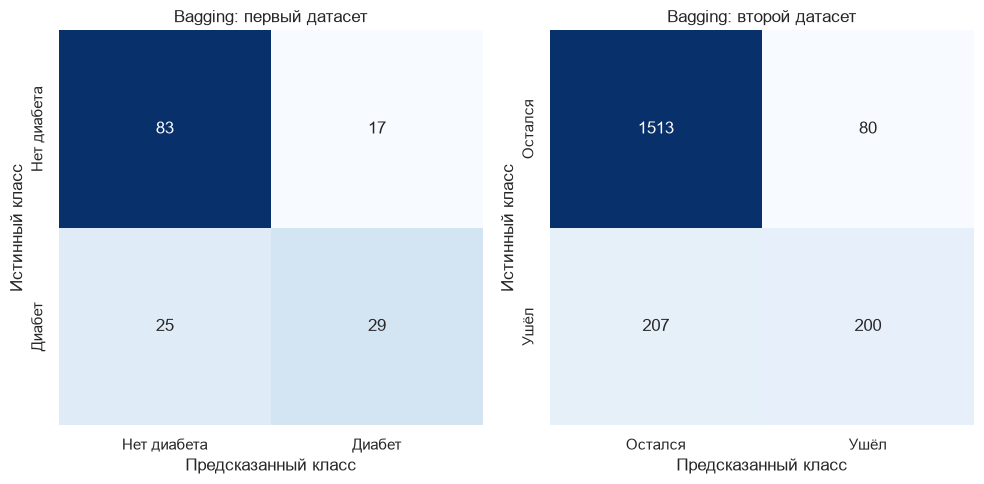

In [132]:
print("ДЛЯ ПЕРВОГО ДАТАСЕТА:")
model1_bag = BaggingClassifier(n_estimators=BAG_n1, random_state=RANDOM_SEED)
model1_bag.fit(X_train1, y_train1)
y1_pred = model1_bag.predict(X_test1)
print(classification_report(y_test1, y1_pred))

print("   ")
print("ДЛЯ ВТОРОГО ДАТАСЕТА:")
model2_bag = BaggingClassifier(n_estimators=BAG_n2, random_state=RANDOM_SEED)
model2_bag.fit(X_train2, y_train2)
y2_pred = model2_bag.predict(X_test2)
print(classification_report(y_test2, y2_pred))

models['bag_1'] = model1_bag
models['bag_2'] = model2_bag


fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, y_true, y_pred, names, title in [
    (axes[0], y_test1, y1_pred, class_names1, 'Bagging: первый датасет'),
    (axes[1], y_test2, y2_pred, class_names2, 'Bagging: второй датасет'),
]:
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
                cbar=False, xticklabels=names, yticklabels=names, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')

plt.tight_layout()
plt.show()

2. Градиентный бустинг (Boosting) — Использование внешних библиотек
Обучить модели градиентного бустинга, используя две специализированные библиотеки (вне scikit-learn):
* XGBoost (класс XGBClassifier)
* LightGBM (класс LGBMClassifier)

Примечание: Для выбранных моделей выполнить базовую настройку критичных параметров (количество итераций/деревьев, скорость обучения learning_rate, глубина деревьев).

## LightGBM (класс LGBMClassifier)

Подбор параметров

In [124]:
from lightgbm import LGBMClassifier

print("ДЛЯ ПЕРВОГО ДАТАСЕТА:")
lgbm = LGBMClassifier(random_state=RANDOM_SEED, verbose=-1)

lgbm_n1, _ = cross_valid(lgbm, 'n_estimators', [50, 100, 200, 300], X_train1, y_train1)
lgbm.set_params(n_estimators=lgbm_n1)

lgbm_lr1, _ = cross_valid(lgbm, 'learning_rate', [0.01, 0.03, 0.05, 0.1, 0.3], X_train1, y_train1)
lgbm.set_params(learning_rate=lgbm_lr1)

lgbm_d1, lgbm_score1 = cross_valid(lgbm, 'max_depth', [2, 3, 4, 5, 7], X_train1, y_train1)
lgbm.set_params(max_depth=lgbm_d1)
print(f"Лучшее n_estimators - {lgbm_n1}, лучшее learning_rate - {lgbm_lr1}, "
      f"лучшее max_depth - {lgbm_d1}, лучшее среднее точности - {lgbm_score1}")

print("ДЛЯ ВТОРОГО ДАТАСЕТА:")
lgbm2 = LGBMClassifier(random_state=RANDOM_SEED, verbose=-1)

lgbm_n2, _ = cross_valid(lgbm2, 'n_estimators', [50, 100, 200, 300], X_train2, y_train2)
lgbm2.set_params(n_estimators=lgbm_n2)

lgbm_lr2, _ = cross_valid(lgbm2, 'learning_rate', [0.01, 0.03, 0.05, 0.1, 0.3], X_train2, y_train2)
lgbm2.set_params(learning_rate=lgbm_lr2)

lgbm_d2, lgbm_score2 = cross_valid(lgbm2, 'max_depth', [2, 3, 4, 5, 7], X_train2, y_train2)
lgbm2.set_params(max_depth=lgbm_d2)
print(f"Лучшее n_estimators - {lgbm_n2}, лучшее learning_rate - {lgbm_lr2}, "
      f"лучшее max_depth - {lgbm_d2}, лучшее среднее точности - {lgbm_score2}")

ДЛЯ ПЕРВОГО ДАТАСЕТА:
Начался подбор...
Подбор закончен.
Начался подбор...
Подбор закончен.
Начался подбор...
Подбор закончен.
Лучшее n_estimators - 50, лучшее learning_rate - 0.03, лучшее max_depth - 4, лучшее среднее точности - 0.7802079168332667
ДЛЯ ВТОРОГО ДАТАСЕТА:
Начался подбор...
Подбор закончен.
Начался подбор...
Подбор закончен.
Начался подбор...
Подбор закончен.
Лучшее n_estimators - 50, лучшее learning_rate - 0.05, лучшее max_depth - 5, лучшее среднее точности - 0.860625


ДЛЯ ПЕРВОГО ДАТАСЕТА:
              precision    recall  f1-score   support

           0       0.79      0.87      0.83       100
           1       0.70      0.57      0.63        54

    accuracy                           0.77       154
   macro avg       0.75      0.72      0.73       154
weighted avg       0.76      0.77      0.76       154

   
ДЛЯ ВТОРОГО ДАТАСЕТА:
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.81      0.43      0.57       407

    accuracy                           0.86      2000
   macro avg       0.84      0.70      0.74      2000
weighted avg       0.86      0.86      0.85      2000



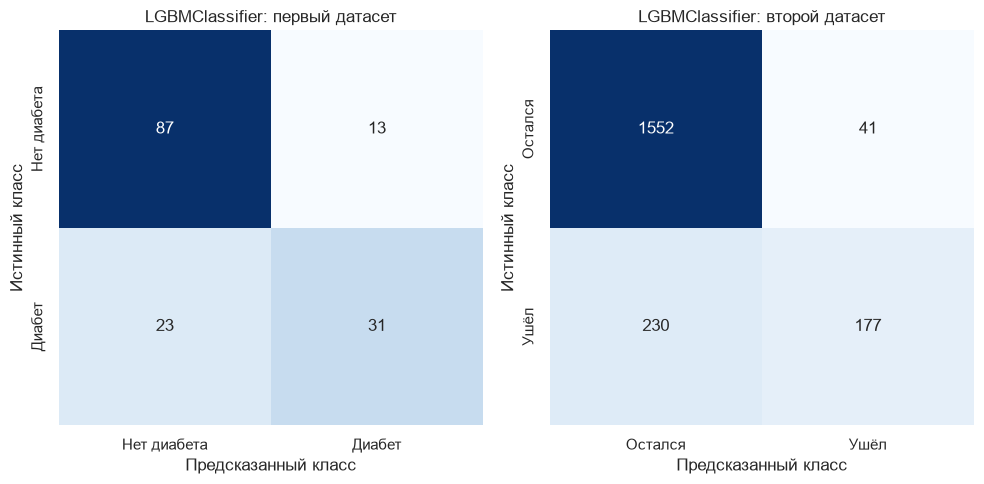

In [133]:
print("ДЛЯ ПЕРВОГО ДАТАСЕТА:")
model1_lgbm = LGBMClassifier(n_estimators=lgbm_n1, learning_rate=lgbm_lr1,
                             max_depth=lgbm_d1, random_state=RANDOM_SEED, verbose=-1)
model1_lgbm.fit(X_train1, y_train1)
y1_pred = model1_lgbm.predict(X_test1)
print(classification_report(y_test1, y1_pred))

print("   ")
print("ДЛЯ ВТОРОГО ДАТАСЕТА:")
model2_lgbm = LGBMClassifier(n_estimators=lgbm_n2, learning_rate=lgbm_lr2,
                             max_depth=lgbm_d2, random_state=RANDOM_SEED, verbose=-1)
model2_lgbm.fit(X_train2, y_train2)
y2_pred = model2_lgbm.predict(X_test2)
print(classification_report(y_test2, y2_pred))

models['lgbm_df1'] = model1_lgbm
models['lgbm_df2'] = model2_lgbm

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, y_true, y_pred, names, title in [
    (axes[0], y_test1, y1_pred, class_names1, 'LGBMClassifier: первый датасет'),
    (axes[1], y_test2, y2_pred, class_names2, 'LGBMClassifier: второй датасет'),
]:
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
                cbar=False, xticklabels=names, yticklabels=names, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')

plt.tight_layout()
plt.show()

## XGBoost (класс XGBClassifier)

Подбор параметров

In [127]:
from xgboost import XGBClassifier

print("ДЛЯ ПЕРВОГО ДАТАСЕТА:")
xgb = XGBClassifier(random_state=RANDOM_SEED, verbosity=0)

xgb_n1, _ = cross_valid(xgb, 'n_estimators', [50, 100, 200, 300], X_train1, y_train1)
xgb.set_params(n_estimators=xgb_n1)

xgb_lr1, _ = cross_valid(xgb, 'learning_rate', [0.01, 0.03, 0.05, 0.1, 0.3], X_train1, y_train1)
xgb.set_params(learning_rate=xgb_lr1)

xgb_d1, xgb_score1 = cross_valid(xgb, 'max_depth', [2, 3, 4, 5, 7], X_train1, y_train1)
xgb.set_params(max_depth=xgb_d1)
print(f"Лучшее n_estimators - {xgb_n1}, лучшее learning_rate - {xgb_lr1}, "
      f"лучшее max_depth - {xgb_d1}, лучшее среднее точности - {xgb_score1}")

print("ДЛЯ ВТОРОГО ДАТАСЕТА:")
xgb2 = XGBClassifier(random_state=RANDOM_SEED, verbosity=0)

xgb_n2, _ = cross_valid(xgb2, 'n_estimators', [50, 100, 200, 300], X_train2, y_train2)
xgb2.set_params(n_estimators=xgb_n2)

xgb_lr2, _ = cross_valid(xgb2, 'learning_rate', [0.01, 0.03, 0.05, 0.1, 0.3], X_train2, y_train2)
xgb2.set_params(learning_rate=xgb_lr2)

xgb_d2, xgb_score2 = cross_valid(xgb2, 'max_depth', [2, 3, 4, 5, 7], X_train2, y_train2)
xgb2.set_params(max_depth=xgb_d2)
print(f"Лучшее n_estimators - {xgb_n2}, лучшее learning_rate - {xgb_lr2}, "
      f"лучшее max_depth - {xgb_d2}, лучшее среднее точности - {xgb_score2}")

ДЛЯ ПЕРВОГО ДАТАСЕТА:
Начался подбор...
Подбор закончен.
Начался подбор...
Подбор закончен.
Начался подбор...
Подбор закончен.
Лучшее n_estimators - 300, лучшее learning_rate - 0.05, лучшее max_depth - 2, лучшее среднее точности - 0.7606290817006531
ДЛЯ ВТОРОГО ДАТАСЕТА:
Начался подбор...
Подбор закончен.
Начался подбор...
Подбор закончен.
Начался подбор...
Подбор закончен.
Лучшее n_estimators - 50, лучшее learning_rate - 0.05, лучшее max_depth - 5, лучшее среднее точности - 0.8615


ДЛЯ ПЕРВОГО ДАТАСЕТА:
              precision    recall  f1-score   support

           0       0.79      0.85      0.82       100
           1       0.67      0.57      0.62        54

    accuracy                           0.75       154
   macro avg       0.73      0.71      0.72       154
weighted avg       0.75      0.75      0.75       154

   
ДЛЯ ВТОРОГО ДАТАСЕТА:
              precision    recall  f1-score   support

           0       0.87      0.98      0.92      1593
           1       0.83      0.44      0.58       407

    accuracy                           0.87      2000
   macro avg       0.85      0.71      0.75      2000
weighted avg       0.86      0.87      0.85      2000



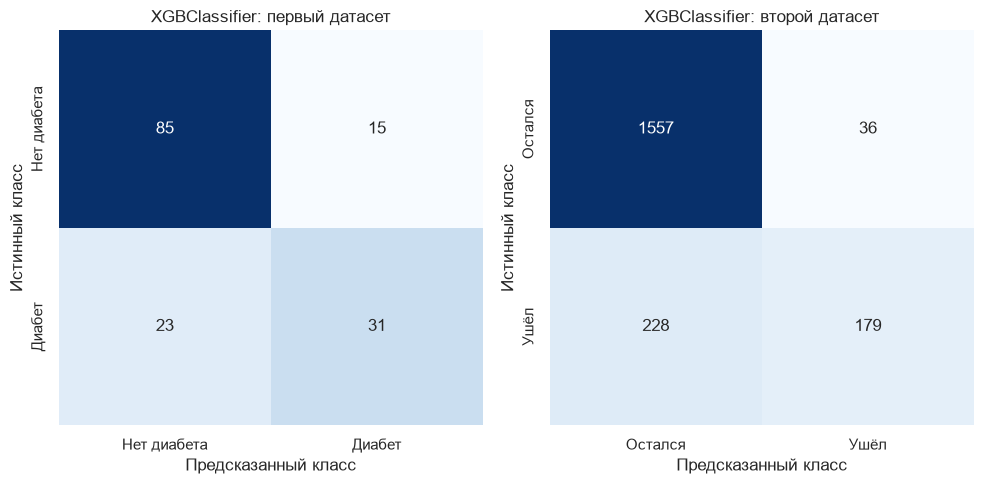

In [134]:
print("ДЛЯ ПЕРВОГО ДАТАСЕТА:")
model1_xgb = XGBClassifier(n_estimators=xgb_n1, learning_rate=xgb_lr1,
                           max_depth=xgb_d1, random_state=RANDOM_SEED, verbosity=0)
model1_xgb.fit(X_train1, y_train1)
y1_pred = model1_xgb.predict(X_test1)
print(classification_report(y_test1, y1_pred))

print("   ")
print("ДЛЯ ВТОРОГО ДАТАСЕТА:")
model2_xgb = XGBClassifier(n_estimators=xgb_n2, learning_rate=xgb_lr2,
                           max_depth=xgb_d2, random_state=RANDOM_SEED, verbosity=0)
model2_xgb.fit(X_train2, y_train2)
y2_pred = model2_xgb.predict(X_test2)
print(classification_report(y_test2, y2_pred))

models['xgb_df1'] = model1_xgb
models['xgb_df2'] = model2_xgb

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, y_true, y_pred, names, title in [
    (axes[0], y_test1, y1_pred, class_names1, 'XGBClassifier: первый датасет'),
    (axes[1], y_test2, y2_pred, class_names2, 'XGBClassifier: второй датасет'),
]:
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
                cbar=False, xticklabels=names, yticklabels=names, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')

plt.tight_layout()
plt.show()

3. Стэкинг (Stacking) - можно использовать scikit-learn
Построить многоуровневый ансамбль (стэкинг).
В качестве базовых моделей (Level 0) использовать лучшие классические алгоритмы, оптимизированные в лабораторной работе №4 (например, SVM, Тuned Decision Tree).
В качестве мета-модели (Level 1) использовать логистическую регрессию или неглубокое дерево решений для агрегации прогнозов. Разрешается использовать StackingClassifier из scikit-learn либо реализовать логику мета-обучения вручную через фолды.

In [138]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import StackingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# лучшие параметры из лабы №4
svm_params1 = {'C': 0.1, 'kernel': 'linear'}
svm_params2 = {'C': 1, 'kernel': 'rbf'}
mlp_params = {'activation': 'relu', 'hidden_layer_sizes': (50,)}   # одинаковые для обоих датасетов

def make_stack(svm_params, mlp_params):
    base_models = [
        ('svm', make_pipeline(StandardScaler(),
                              SVC(**svm_params, probability=True, random_state=RANDOM_SEED))),
        ('mlp', make_pipeline(StandardScaler(),
                              MLPClassifier(**mlp_params, max_iter=1000, random_state=RANDOM_SEED))),
    ]
    return StackingClassifier(
        estimators=base_models,
        final_estimator=LogisticRegression(max_iter=1000),
        cv=5,
    )

print("ДЛЯ ПЕРВОГО ДАТАСЕТА:")
stack = make_stack(svm_params1, mlp_params)
st_meta1, st_score1 = cross_valid(stack, 'final_estimator__C', [0.01, 0.1, 1, 10, 100], X_train1, y_train1)
print(f"Лучшее C мета-модели - {st_meta1}, лучшее среднее точности - {st_score1}")

print("ДЛЯ ВТОРОГО ДАТАСЕТА:")
stack2 = make_stack(svm_params2, mlp_params)
st_meta2, st_score2 = cross_valid(stack2, 'final_estimator__C', [0.01, 0.1, 1, 10, 100], X_train2, y_train2)
print(f"Лучшее C мета-модели - {st_meta2}, лучшее среднее точности - {st_score2}")

ДЛЯ ПЕРВОГО ДАТАСЕТА:
Начался подбор...
Подбор закончен.
Лучшее C мета-модели - 1, лучшее среднее точности - 0.7883646541383447
ДЛЯ ВТОРОГО ДАТАСЕТА:
Начался подбор...
Подбор закончен.
Лучшее C мета-модели - 0.1, лучшее среднее точности - 0.8568749999999999


ДЛЯ ПЕРВОГО ДАТАСЕТА:


/home/polinwq_534/anaconda3/envs/lab3/lib/python3.14t/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/polinwq_534/anaconda3/envs/lab3/lib/python3.14t/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/polinwq_534/anaconda3/envs/lab3/lib/python3.14t/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/polinwq_534/anaconda3/envs/lab3/lib/python3.14t/site-packages/sklearn/svm/_base.py:236: Future

              precision    recall  f1-score   support

           0       0.76      0.83      0.79       100
           1       0.62      0.52      0.57        54

    accuracy                           0.72       154
   macro avg       0.69      0.67      0.68       154
weighted avg       0.71      0.72      0.71       154

   
ДЛЯ ВТОРОГО ДАТАСЕТА:


/home/polinwq_534/anaconda3/envs/lab3/lib/python3.14t/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/polinwq_534/anaconda3/envs/lab3/lib/python3.14t/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/polinwq_534/anaconda3/envs/lab3/lib/python3.14t/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/polinwq_534/anaconda3/envs/lab3/lib/python3.14t/site-packages/sklearn/svm/_base.py:236: Future

              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.79      0.46      0.58       407

    accuracy                           0.86      2000
   macro avg       0.83      0.71      0.75      2000
weighted avg       0.86      0.86      0.85      2000



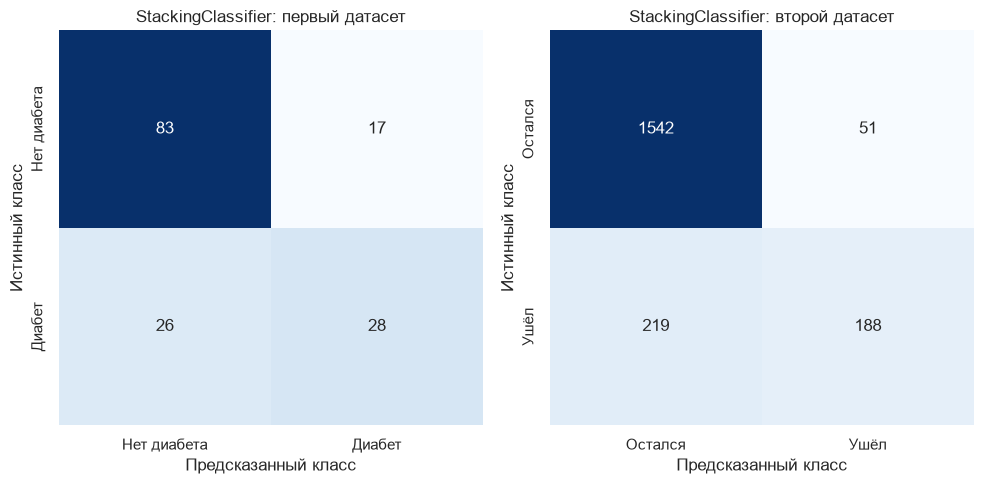

In [139]:
print("ДЛЯ ПЕРВОГО ДАТАСЕТА:")
model1_stack = make_stack(svm_params1, mlp_params)
model1_stack.set_params(final_estimator__C=st_meta1)
model1_stack.fit(X_train1, y_train1)
y1_pred = model1_stack.predict(X_test1)
print(classification_report(y_test1, y1_pred))

print("   ")
print("ДЛЯ ВТОРОГО ДАТАСЕТА:")
model2_stack = make_stack(svm_params2, mlp_params)
model2_stack.set_params(final_estimator__C=st_meta2)
model2_stack.fit(X_train2, y_train2)
y2_pred = model2_stack.predict(X_test2)
print(classification_report(y_test2, y2_pred))

models['stack_df1'] = model1_stack
models['stack_df2'] = model2_stack

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, y_true, y_pred, names, title in [
    (axes[0], y_test1, y1_pred, class_names1, 'StackingClassifier: первый датасет'),
    (axes[1], y_test2, y2_pred, class_names2, 'StackingClassifier: второй датасет'),
]:
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
                cbar=False, xticklabels=names, yticklabels=names, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')

plt.tight_layout()
plt.show()

## Часть 3. Оценка качества и сквозной сравнительный анализ
Для каждого реализованного ансамбля (Bagging, XGBoost/LightGBM/CatBoost, Stacking) на тестовой выборке необходимо:
Построить и визуализировать матрицу неточностей (Confusion Matrix).
Вывести структурированный классификационный отчет (Classification Report) с метриками Accuracy, Precision, Recall и F1-score.
Глобальное сравнение: Создать итоговую сводную таблицу (pandas.DataFrame), в которой сопоставить метрики качества лучших классических моделей из ЛР №4 и новых ансамблевых моделей из ЛР №5.

In [152]:
titles = {'bag': 'Bagging', 'xgb': 'XGBoost', 'lgbm': 'LightGBM', 'stack': 'Stacking'}
tests = {'df1': (X_test1, y_test1), 'df2': (X_test2, y_test2)}

rows = []
for name, model in models.items():
    algo, ds = name.split('_')
    if not ds.startswith('df'): 
        ds = 'df' + ds
    X_t, y_t = tests[ds]
    pred = model.predict(X_t)
    rows.append({
        'Датасет': ds,
        'Модель': titles[algo],
        'Тип': 'Ансамбль',
        'Accuracy': accuracy_score(y_t, pred),
        'Precision': precision_score(y_t, pred),
        'Recall': recall_score(y_t, pred),
        'F1': f1_score(y_t, pred),
    })

ens = pd.DataFrame(rows)

In [153]:
lab4_1 = pd.read_csv('lab4_results_df1.csv').rename(columns={'Model': 'Модель'})
lab4_2 = pd.read_csv('lab4_results_df2.csv').rename(columns={'Model': 'Модель'})

lab4_1['Датасет'] = 'df1'
lab4_2['Датасет'] = 'df2'
lab4_1['Тип'] = lab4_2['Тип'] = 'Классика'

summary = pd.concat([lab4_1, lab4_2, ens], ignore_index=True)
summary = summary[['Датасет', 'Тип', 'Модель', 'Accuracy', 'Precision', 'Recall', 'F1']].round(3)
summary.sort_values(['Датасет', 'F1'], ascending=[True, False])

,Датасет,Тип,Модель,Accuracy,Precision,Recall,F1
10,df1,Ансамбль,LightGBM,0.766,0.705,0.574,0.633
12,df1,Ансамбль,XGBoost,0.753,0.674,0.574,0.620
0,df1,Классика,kNN,0.734,0.633,0.574,0.602
3,df1,Классика,MLP,0.727,0.625,0.556,0.588
8,df1,Ансамбль,Bagging,0.727,0.630,0.537,0.580
14,df1,Ансамбль,Stacking,0.721,0.622,0.519,0.566
2,df1,Классика,SVM,0.708,0.605,0.481,0.536
1,df1,Классика,Decision Tree,0.688,0.636,0.259,0.368
7,df2,Классика,MLP,0.861,0.717,0.523,0.605
9,df2,Ансамбль,Bagging,0.856,0.714,0.491,0.582


## Часть 4. Дополнительное задание (Необязательное требование)
Интерактивный бенчмарк на Streamlit: Разработайте веб-приложение, нацеленное на визуальное сравнение «Классика vs Ансамбли».
Функционал приложения:
Загрузка тестового подмножества данных.
Возможность интерактивно отмечать галочками (st.checkbox()), какие модели (и классические, и ансамблевые) включить в текущий цикл сравнения.
Динамическое построение кривых ошибок (например, ROC-AUC кривых) или сравнительных столбчатых диаграмм метрик для всех выбранных моделей на одном полотне.